# Explorer l'accidentologie avec Python

Ce notebook montre comment charger, explorer et représenter les données BAAC avec l'API publique `accidentologie`. Le cas d'étude porte sur les **33 communes de la CARA**, de **2020 à 2024 inclus**. Le nom du territoire, ses codes INSEE et la période sont regroupés dans la cellule de configuration afin d'adapter l'analyse à un autre périmètre.

> Les résultats décrivent les accidents et victimes observés. Sans données de trafic, de population exposée ou de kilomètres parcourus, ils ne mesurent pas un risque individuel absolu.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from accidentologie import (
    get_dataframe,
    get_fatalities_by_user_type,
    get_vehicle_severity_table,
    get_victim_dataframe,
    plot_accident_per_year,
    plot_fatalities_by_user_type,
    plot_mobility_severity,
    plot_monthly_seasonality,
    plot_severity_map,
    plot_severity_map_static,
    plot_victim_age_pyramid,
    plot_vehicle_severity_table,
    plot_weekday_hour_heatmap,
)

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 30)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "notebooks" / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TERRITORY_NAME = "Communauté d'agglomération Royan Atlantique (CARA)"
COMMUNES = (
    "17015", "17021", "17034", "17060", "17064", "17068", "17079",
    "17098", "17119", "17131", "17152", "17155", "17160", "17183",
    "17151", "17452", "17097", "17225", "17228", "17230", "17247",
    "17248", "17306", "17307", "17311", "17333", "17380", "17393",
    "17409", "17421", "17425", "17437", "17461",
)
YEARS = range(2020, 2025)
PERIOD_LABEL = f"{min(YEARS)}–{max(YEARS)}"

## 1. Charger les accidents

`get_dataframe` retourne une ligne par accident. Les communes sont filtrées avec leurs codes INSEE et les anciens schémas BAAC sont normalisés automatiquement.

In [2]:
accidents = get_dataframe(
    years=YEARS,
    communes=COMMUNES,
    data_dir=DATA_DIR,
)

summary = pd.DataFrame({
    "indicateur": [
        "Accidents",
        "Accidents géolocalisés",
        "Accidents mortels",
        "Personnes tuées",
        "Véhicules enregistrés",
    ],
    "valeur": [
        len(accidents),
        int(accidents["has_coordinates"].sum()),
        int(accidents["severity"].eq("Mortel").sum()),
        int(accidents["number_killed"].sum()),
        int(accidents["number_vehicles"].sum()),
    ],
})
summary

,indicateur,valeur
0,Accidents,409
1,Accidents géolocalisés,409
2,Accidents mortels,26
3,Personnes tuées,29
4,Véhicules enregistrés,698


In [3]:
accidents.head()

,accident_id,year,date,time,department_code,commune_code,address,latitude,longitude,has_coordinates,severity_code,severity,number_killed,number_hospitalized,number_slightly_injured,number_uninjured,number_users,number_vehicles,vehicle_codes,vehicle_types
0,202000000691,2020,2020-08-23,10:20,17,17306,PONTAILLAC (DE) (AVENUE),45.620320,-1.035360,True,4,Léger,0,0,1,1,2,2,60;7,Engin de déplacement personnel sans moteur ; V...
1,202000001446,2020,2020-09-19,16:30,17,17333,COTE DE BEAUTE (BOULEVARD),45.597580,-0.992560,True,4,Léger,0,0,2,1,3,2,33;7,Motocyclette > 125 cm³ ; Voiture particulière
2,202000001447,2020,2020-09-18,18:50,17,17306,TARTANE (DE LA),45.619030,-1.030570,True,4,Léger,0,0,1,3,4,2,1;10,"Bicyclette ; Véhicule utilitaire 1,5–3,5 t"
3,202000002109,2020,2020-10-17,16:30,17,17452,D25,45.762613,-1.215513,True,3,Grave non mortel,0,1,0,0,1,1,33,Motocyclette > 125 cm³
4,202000002697,2020,2020-11-29,13:30,17,17306,PALISSY BERNARD,45.630039,-1.035474,True,4,Léger,0,0,1,1,2,2,10;2,"Cyclomoteur < 50 cm³ ; Véhicule utilitaire 1,5..."


## 2. Construire soi-même un graphique à partir du DataFrame

`get_dataframe` retourne un DataFrame Pandas standard. Cette section agrège les accidents par mois et gravité avec Pandas, puis représente le résultat avec une fonction Matplotlib.

In [4]:
monthly_by_severity = (
    accidents
    .dropna(subset=["date"])
    .assign(month=lambda frame: frame["date"].dt.to_period("M").dt.to_timestamp())
    .groupby(["month", "severity"])["accident_id"]
    .nunique()
    .unstack(fill_value=0)
)

for severity in ["Léger", "Grave non mortel", "Mortel"]:
    if severity not in monthly_by_severity:
        monthly_by_severity[severity] = 0

monthly_by_severity.tail()

severity,Grave non mortel,Léger,Mortel
month,,,
2024-08-01,2,8,1
2024-09-01,4,5,0
2024-10-01,1,2,0
2024-11-01,2,5,2
2024-12-01,0,2,1


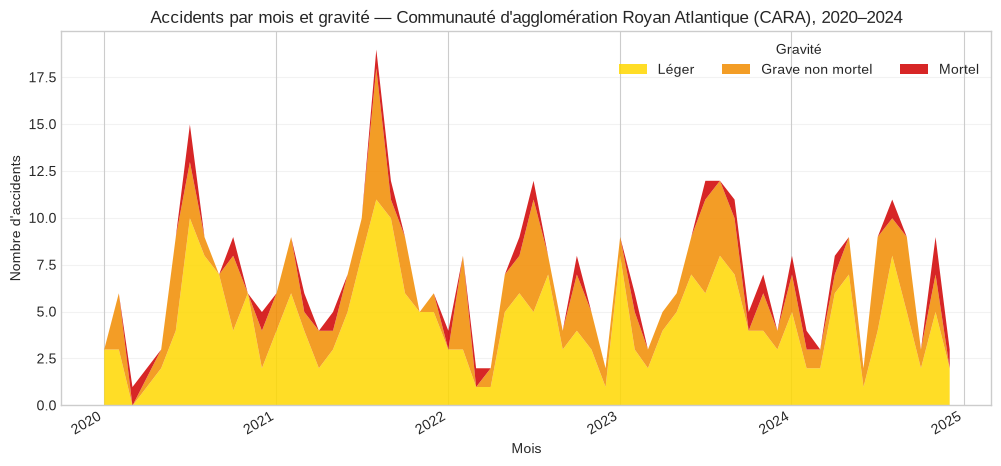

In [5]:
def plot_custom_monthly_timeline(monthly_dataframe):
    """Trace le nombre mensuel d'accidents par niveau de gravité."""
    columns = ["Léger", "Grave non mortel", "Mortel"]
    colors = ["#FFD800", "#F28C00", "#D00000"]
    ax = monthly_dataframe[columns].plot.area(
        stacked=True,
        color=colors,
        figsize=(12, 5.5),
        alpha=0.85,
        linewidth=0,
    )
    ax.set_title(f"Accidents par mois et gravité — {TERRITORY_NAME}, {PERIOD_LABEL}")
    ax.set_xlabel("Mois")
    ax.set_ylabel("Nombre d'accidents")
    ax.legend(title="Gravité", frameon=False, ncol=3)
    ax.grid(axis="y", alpha=0.25)
    return ax

ax = plot_custom_monthly_timeline(monthly_by_severity)
plt.show()

## 3. Évolution annuelle par gravité

Chaque accident est classé une seule fois, selon la conséquence la plus grave parmi ses usagers.

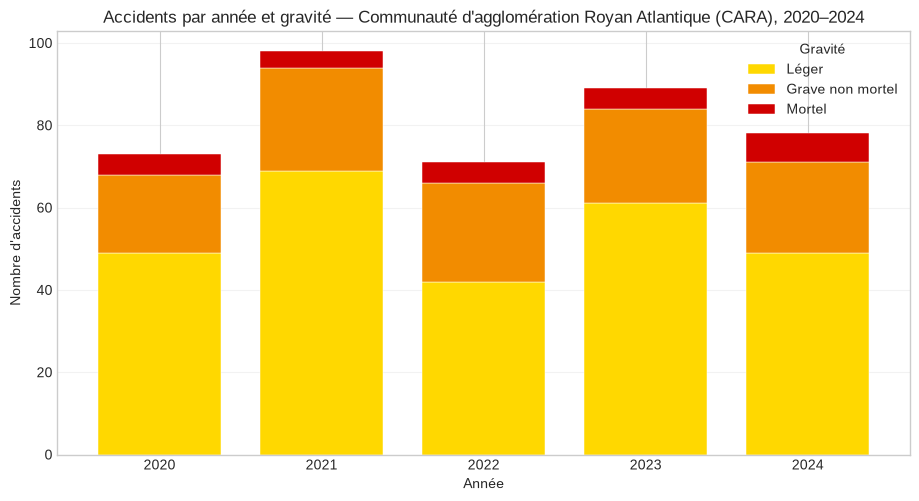

In [6]:
ax = plot_accident_per_year(
    accidents,
    title=f"Accidents par année et gravité — {TERRITORY_NAME}, {PERIOD_LABEL}",
)
ax.figure.set_size_inches(11, 5.5)
plt.show()

## 4. Saisonnalité mensuelle

La matrice permet de repérer les mois chargés sans masquer les différences entre années. Une couleur forte signale davantage d'accidents, pas nécessairement davantage de gravité.

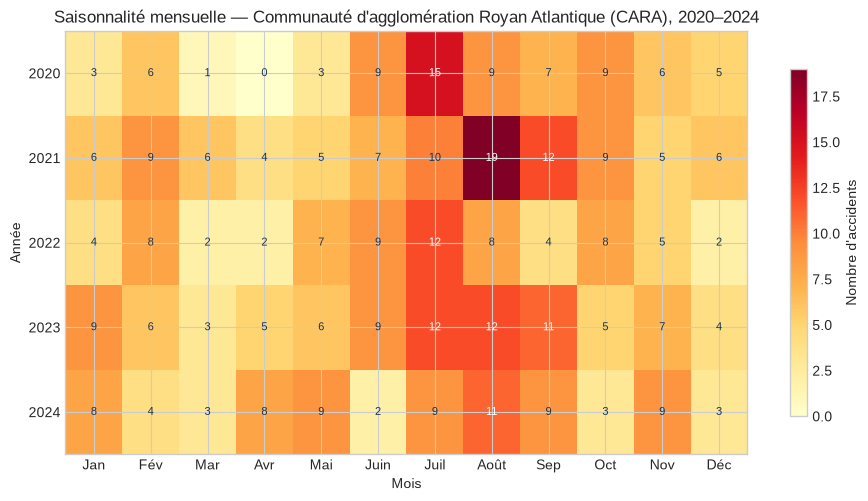

In [7]:
ax = plot_monthly_seasonality(
    accidents,
    title=f"Saisonnalité mensuelle — {TERRITORY_NAME}, {PERIOD_LABEL}",
)
plt.show()

## 5. Répartition par jour de la semaine et heure

Cette heatmap met en évidence les créneaux où les accidents sont les plus nombreux. Elle peut guider une analyse plus fine des trajets domicile-travail, des sorties scolaires ou des périodes de loisirs.

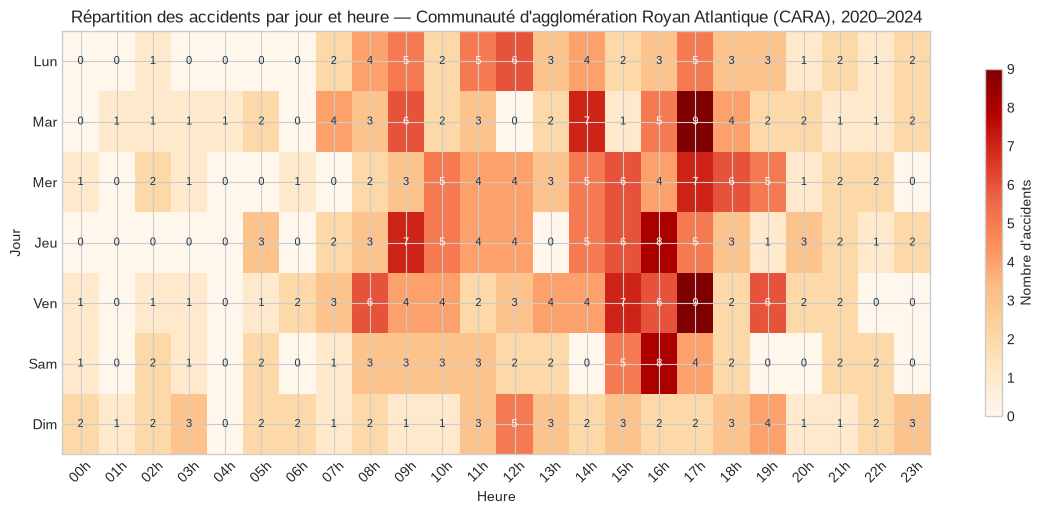

In [8]:
ax = plot_weekday_hour_heatmap(
    accidents,
    title=f"Répartition des accidents par jour et heure — {TERRITORY_NAME}, {PERIOD_LABEL}",
)
plt.show()

## 6. Véhicules impliqués

Un accident impliquant plusieurs types de véhicules apparaît une fois dans chaque catégorie concernée. Les totaux de ce tableau ne sont donc pas des nombres d'accidents distincts.

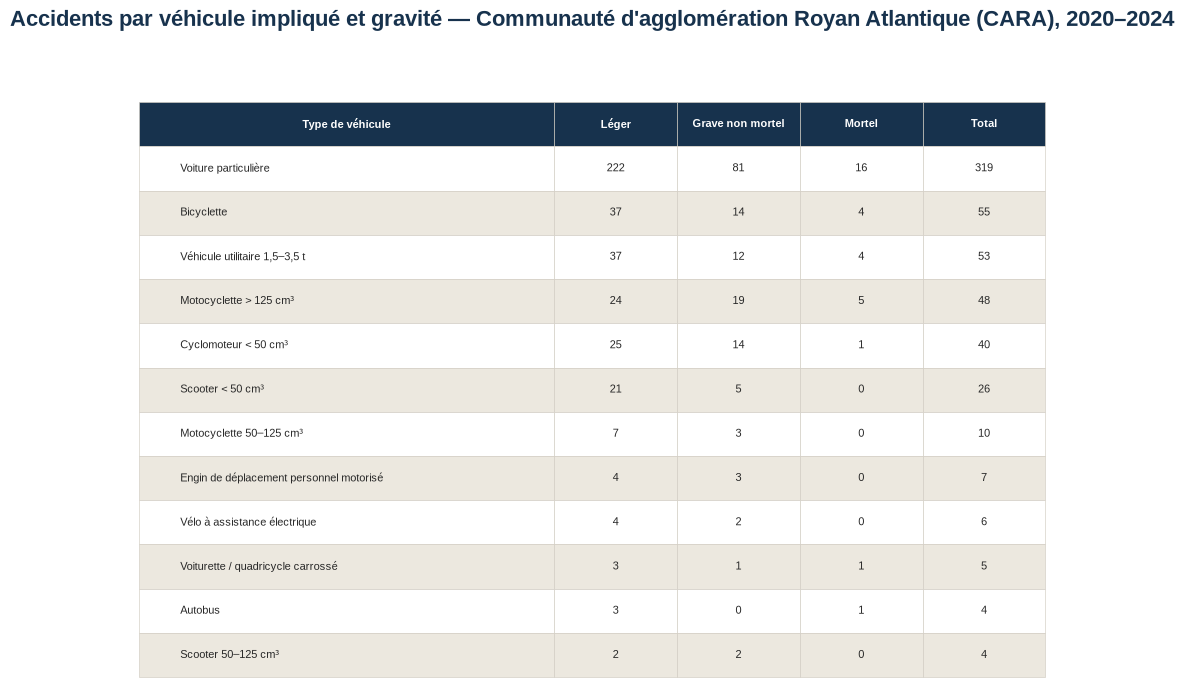

In [9]:
vehicle_table = get_vehicle_severity_table(accidents)
ax = plot_vehicle_severity_table(
    vehicle_table,
    title=f"Accidents par véhicule impliqué et gravité — {TERRITORY_NAME}, {PERIOD_LABEL}",
    max_rows=12,
)
plt.show()

## 7. Charger les usagers et victimes

`get_victim_dataframe` retourne une ligne par usager. Cela permet d'étudier l'âge, le sexe, la catégorie d'usager, le véhicule et le mode de déplacement.

In [10]:
victims = get_victim_dataframe(
    years=YEARS,
    communes=COMMUNES,
    data_dir=DATA_DIR,
)
victims[["year", "severity", "age", "sex", "user_category", "mobility"]].head()

,year,severity,age,sex,user_category,mobility
0,2020,Blessé léger,35.0,Homme,Conducteur,EDP
1,2020,Indemne,69.0,Homme,Conducteur,Voiture / voiturette
2,2020,Indemne,76.0,Homme,Conducteur,Voiture / voiturette
3,2020,Blessé léger,66.0,Homme,Conducteur,Moto / scooter / 3RM
4,2020,Blessé léger,66.0,Femme,Passager,Moto / scooter / 3RM


## 8. Pyramide des âges

La pyramide porte uniquement sur les personnes blessées ou tuées dont l'âge et le sexe sont renseignés. Les hommes sont placés à gauche et les femmes à droite.

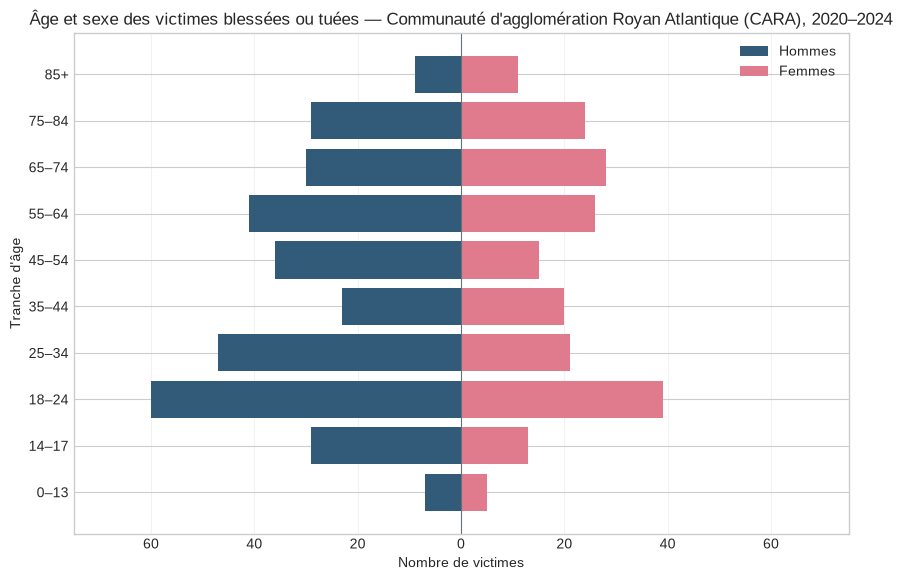

In [11]:
ax = plot_victim_age_pyramid(
    victims,
    title=f"Âge et sexe des victimes blessées ou tuées — {TERRITORY_NAME}, {PERIOD_LABEL}",
)
plt.show()

## 9. Gravité observée par mode de déplacement

Le graphique compare, parmi les victimes blessées ou tuées, la proportion hospitalisée ou décédée. Le seuil de 10 victimes évite d'afficher des pourcentages très instables. **Ce taux n'est pas une probabilité d'accident** : il ne tient pas compte du nombre d'usagers ni des distances parcourues pour chaque mobilité.

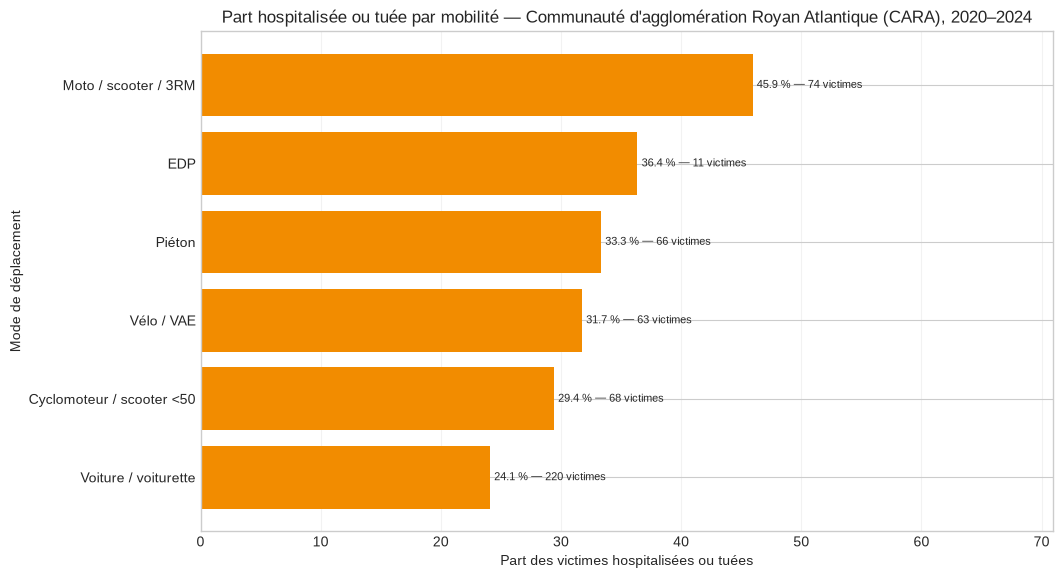

In [12]:
ax = plot_mobility_severity(
    victims,
    min_victims=10,
    title=f"Part hospitalisée ou tuée par mobilité — {TERRITORY_NAME}, {PERIOD_LABEL}",
)
plt.show()

## 10. Personnes tuées par type d'usager

Cette vue compte des personnes, contrairement aux graphiques précédents centrés sur les accidents.

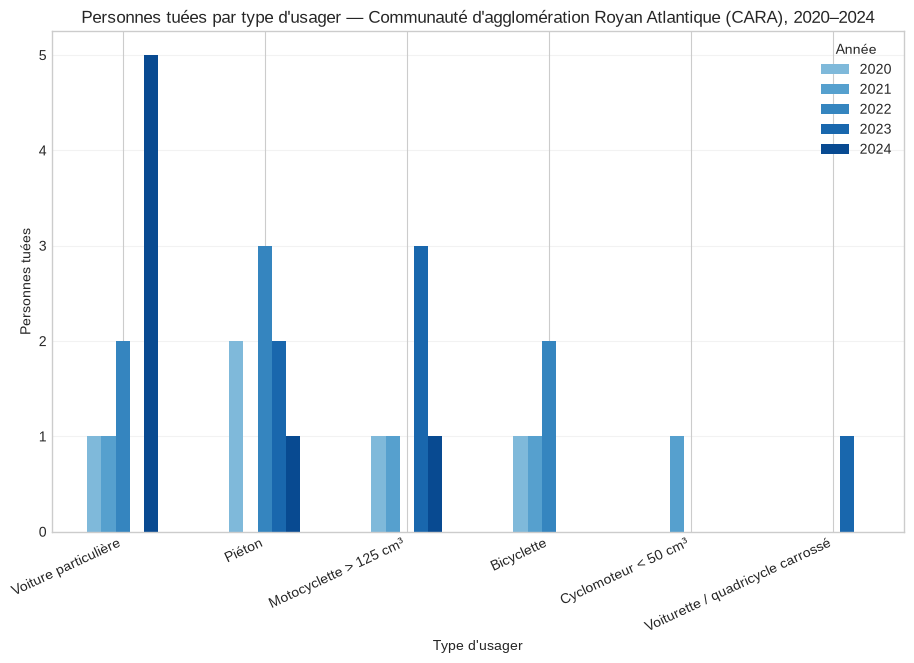

In [13]:
fatalities = get_fatalities_by_user_type(victims)
ax = plot_fatalities_by_user_type(
    fatalities,
    title=f"Personnes tuées par type d'usager — {TERRITORY_NAME}, {PERIOD_LABEL}",
)
plt.show()

## 11. Carte statique

La carte statique est adaptée à une image ou à un rapport PDF. Étoile rouge : mortel ; losange orange : grave non mortel ; rond jaune : léger.

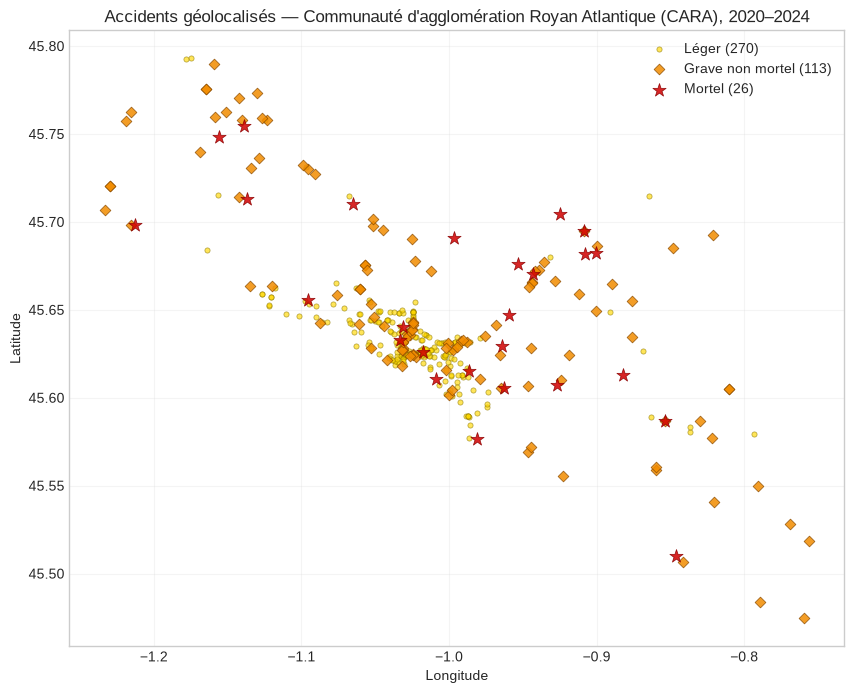

In [14]:
ax = plot_severity_map_static(
    accidents,
    title=f"Accidents géolocalisés — {TERRITORY_NAME}, {PERIOD_LABEL}",
)
ax.figure.set_size_inches(10, 8)
plt.show()

## 12. Carte interactive

Folium produit une carte zoomable avec regroupement des points. La carte est affichée dans le notebook et enregistrée dans `notebooks/outputs/`.

In [15]:
interactive_map = plot_severity_map(
    accidents,
    output=OUTPUT_DIR / "carte_accidents.html",
)
interactive_map

## Pistes d'analyse supplémentaires

- comparer la saisonnalité avant/après 2020 ;
- séparer semaine et week-end selon le mode de déplacement ;
- calculer les indicateurs par commune, puis les rapporter à la population ;
- intégrer des données de trafic pour passer de volumes observés à des taux d'exposition ;
- étudier séparément les accidents impliquant vélos, motos, piétons ou seniors.